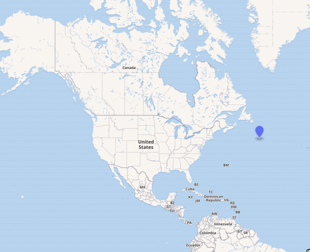




In 4AI3 Assignment 1, we worked with the titanic dataset from Kaggle. I noticed 2 things many of you did.


1.   Per the assignment requirement, you filled the missing values of the **Age** attribute in the very beginning with the avereaged age out of the entire data.
2.   Many of you splitted the **Passager Class** attribute in the dataset into 3 columns: UpperClass, MiddleClass, LowerClass, with their values one-hot encoded.

Do you know why these operations were performed? Or, what will happen if we don't do it? Let's find out.

(ps. The picture above showed where the titanic sunk. I took that from Wikipedia. It's actually not too far from where we are.)


In [1]:
ls

Titanic_LogisticRegression.ipynb  train.csv


In [2]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RepeatedStratifiedKFold
from scipy import stats
import matplotlib.pyplot as plt
from tabulate import tabulate


Let's have a look at the dataset first.


In [3]:
df = pd.read_csv('train.csv')
print(df.keys())
print(tabulate(df.head()))

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')
-  -  -  -  ---------------------------------------------------  ------  --  -  -  ----------------  -------  ----  -
0  1  0  3  Braund, Mr. Owen Harris                              male    22  1  0  A/5 21171          7.25    nan   S
1  2  1  1  Cumings, Mrs. John Bradley (Florence Briggs Thayer)  female  38  1  0  PC 17599          71.2833  C85   C
2  3  1  3  Heikkinen, Miss. Laina                               female  26  0  0  STON/O2. 3101282   7.925   nan   S
3  4  1  1  Futrelle, Mrs. Jacques Heath (Lily May Peel)         female  35  1  0  113803            53.1     C123  S
4  5  0  3  Allen, Mr. William Henry                             male    35  0  0  373450             8.05    nan   S
-  -  -  -  ---------------------------------------------------  ------  --  -  -  ----------------  -------  ----  -


In [4]:
df = df[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']].copy()
nan_counts = df.isna().sum().to_string()
print(f"NaN counts:\n{nan_counts}")
print(f"\nThere are {len(df)} samples in the dataset.")

NaN counts:
Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0

There are 891 samples in the dataset.



Age has 177 missing values. We want to know what attributes are likely related with missing age values. Let's build a correlation matrix.


In [5]:
df['Sex'] = df['Sex'].map({'female': 1, 'male': 0})
df['Pclass'] = df['Pclass'].map({1: 3, 2: 2, 3: 1})
df_new = df.copy()
df_new['Age_NaN'] = df['Age'].isna().astype(int)


Let's take a look at the correlation matrix.


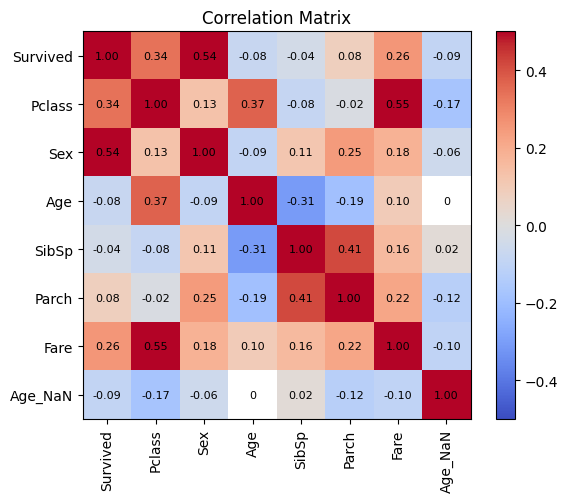


Parch means the # of Parents / Children accompanied the trip. SibSp means Sibilings and Spouse.


In [6]:
corr_matrix = df_new.corr()

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-0.5, vmax=0.5)
plt.colorbar(im, ax=ax)

ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.columns)))
ax.set_xticklabels(corr_matrix.columns, rotation=90)
ax.set_yticklabels(corr_matrix.columns)
ax.set_title('Correlation Matrix')

for i in range(len(corr_matrix.index)):
  for j in range(len(corr_matrix.columns)):
    val = corr_matrix.iloc[i, j]
    text = f"{val:.2f}" if not np.isnan(val) else "0"
    color = "black"
    ax.text(j, i, text, ha="center", va="center", color=color, fontsize=8)

plt.tight_layout()
plt.show()

print("\nParch means the # of Parents / Children accompanied the trip. SibSp means Sibilings and Spouse.")


In the correlation matrix, we just need to focus on the last row (and ignore the last box that is red, that is the correlation with itself). It can be seen that the Age_NaNs are most associated with Pclass (the pink/orange box that says 0.17). Let's take a look at more details.


In [7]:
age_mean_df = df['Age'].mean()
age_mean_uc = df.loc[df['Pclass'] == 1, 'Age'].mean()
age_mean_mc = df.loc[df['Pclass'] == 2, 'Age'].mean()
age_mean_lc = df.loc[df['Pclass'] == 3, 'Age'].mean()

print(f"Dataset mean: {round(age_mean_df)}")
print(f"UpperClass mean: {round(age_mean_uc)} \nMiddleClass mean: {round(age_mean_mc)} \nLowerClass mean: {round(age_mean_lc)}")

Dataset mean: 30
UpperClass mean: 25 
MiddleClass mean: 30 
LowerClass mean: 38



The dataset average is 8 years younger than UpperClass average and 5 years older than LowerClass average. It will not be so accurate to replace the NaNs in the Age attribute with this value. Let's fill the NaNs with the average age from the class subgroups instead. We will do this operation after the train-test split to avoid data leakage.

Good. Now we'll take a look at the second implementation you guys did, which is spliting the Passenger Class into 3 separate columns, UpperClass, MiddleClass, LowerClass. Was that necessary?

In the assignment, we only worked with Sex, Age, Class, so let's filter out the unused attributes. We will make two sets of training data X1 and X2, where X1 contains only one Pclass column, and X2 contains 3 columns. We will then train two models accordingly, model 1 and 2.

In [8]:
X1 = df[['Sex', 'Age', 'Pclass']].copy()
y = df['Survived'].copy()

X2 = df[['Sex', 'Age']].copy()
X2['UpperClass'] = (df['Pclass'] == 1).astype(int)
X2['MiddleClass'] = (df['Pclass'] == 2).astype(int)
# dropped X2['LowerClass'] = (df['Pclass'] == 3).astype(int) to avoid multicollinearity

Now let's train the logsitc regression models. Model 1 will be trained the data with on one class column, and model 2 will be trained on the data with three class columns. We will do a 5-fold cross validation to evaluate these models and repeat the experiment 20 times.

In [9]:
scores_m1 = []
scores_m2 = []
m1_wins = 0
m2_wins = 0
ties = 0

n_splits = 5
n_repeats = 20

rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=42)

for train_idx, test_idx in rskf.split(X1, y):

  X_train  = X1.iloc[train_idx].copy()
  X_test   = X1.iloc[test_idx].copy()
  X2_train = X2.iloc[train_idx].copy()
  X2_test  = X2.iloc[test_idx].copy()

  class_age_means = X_train.groupby('Pclass')['Age'].mean()

  X_train['Age']  = X_train['Age'].fillna(X_train['Pclass'].map(class_age_means))
  X_test['Age']   = X_test['Age'].fillna(X_test['Pclass'].map(class_age_means))
  X2_train['Age'] = X_train['Age']
  X2_test['Age']  = X_test['Age']

  y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

  scaler1 = StandardScaler()
  X_train_scaled = scaler1.fit_transform(X_train)
  X_test_scaled  = scaler1.transform(X_test)

  scaler2 = StandardScaler()
  X2_train_scaled = scaler2.fit_transform(X2_train)
  X2_test_scaled  = scaler2.transform(X2_test)

  model1 = LogisticRegression().fit(X_train_scaled, y_train)
  model2 = LogisticRegression().fit(X2_train_scaled, y_train)

  s1 = model1.score(X_test_scaled, y_test) * 100
  s2 = model2.score(X2_test_scaled, y_test) * 100
  scores_m1.append(s1)
  scores_m2.append(s2)

  if s1 > s2:
      m1_wins += 1
  elif s2 > s1:
      m2_wins += 1
  else:
      ties += 1

Now the experiment is done, let's look at the results.

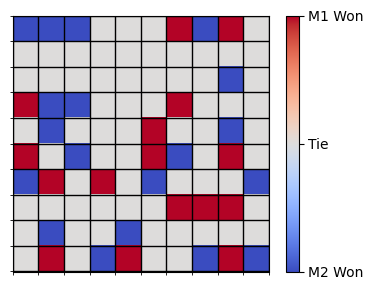

Model 1 won: 16 % | Model 2 won: 19 % | Tied: 65 %
Mean Accuracy -> Model 1: 79.56% | Model 2: 79.57%


In [10]:
diffs = np.array(scores_m1) - np.array(scores_m2)
total_runs = len(diffs)

cols = int(np.ceil(np.sqrt(total_runs)))
rows = int(np.ceil(total_runs / cols))

padded = np.full(rows * cols, np.nan)
padded[:total_runs] = np.sign(diffs)
win_grid = padded.reshape(rows, cols)

fig, ax = plt.subplots(figsize=(4, 3))
im = ax.imshow(win_grid, cmap='coolwarm', vmin=-1, vmax=1)
cbar = plt.colorbar(im, ax=ax, ticks=[-1, 0, 1])
cbar.ax.set_yticklabels(['M2 Won', 'Tie', 'M1 Won'])

ax.set_xticks(np.arange(-0.5, cols, 1), minor=True)
ax.set_yticks(np.arange(-0.5, rows, 1), minor=True)
ax.grid(which='minor', color='black', linestyle='-', linewidth=1)
ax.set_xticks([])
ax.set_yticks([])

plt.tight_layout()
plt.show()

print("="*50)
print(f"Model 1 won: {round(m1_wins*100/total_runs)} % | Model 2 won: {round(m2_wins*100/total_runs)} % | Tied: {round(ties*100/total_runs)} %")
print(f"Mean Accuracy -> Model 1: {np.mean(scores_m1):.2f}% | Model 2: {np.mean(scores_m2):.2f}%")
print("="*50)

It does seem like we are better off splitting the column. Let's use a t-test to verify if this conclusion is statistically significant.

In [11]:
d_bar = np.mean(diffs)
s_var = np.var(diffs, ddof=1)
t_stat = d_bar / np.sqrt((1 / len(diffs) + (1/n_splits) / (1-(1/n_splits))) * s_var) # Nadeau & Bengio t-test
p_val = 2 * (1 - stats.t.cdf(abs(t_stat), df=len(diffs) - 1))
print(f"Mean diff: {d_bar:.4f}%\nt-stat: {t_stat:.4f}\np-value: {p_val:.4f}")

Mean diff: -0.0169%
t-stat: -0.0809
p-value: 0.9357


OK, the t-test (high p-value) suggests that the differences we have observed here are not statistically significant. But if that's the case, doesn't it mean we don't actually need to split the **Passenger Class** column into three columns: UpperClass, MiddleClass, LowerClass?

That's right. And this is because in this dataset, among UpperClass, MiddleClass, and LowerClass, there is a linear relationship. So whether or not we use one variable (with the 3 classes sharing the same weight) or three variables with three different weights, the results will be similar.

In the end, let's us take a look at what the model thinks are the most important factors for survival on the Titanic! We will do that by training a model on the (almost) full dataset.

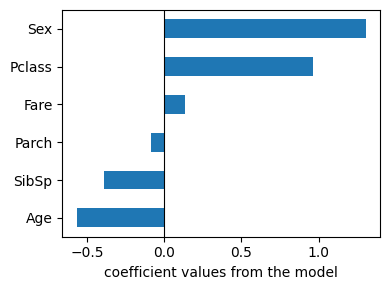


Parch means the # of Parents / Children accompanied the trip. SibSp means Sibilings and Spouse.


In [12]:
X_full = df_new[['Sex', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']].copy()
class_age_means = df.groupby('Pclass')['Age'].mean()
X_full['Age'] = X_full['Age'].fillna(df['Pclass'].map(class_age_means))
y_full = df_new['Survived'].copy()

scaler_full = StandardScaler()
X_full_scaled = scaler_full.fit_transform(X_full)

model_full = LogisticRegression().fit(X_full_scaled, y_full)

coeffs = pd.Series(model_full.coef_[0], index=X_full.columns).sort_values()

fig, ax = plt.subplots(figsize=(4, 3))
coeffs.plot(kind='barh', ax=ax)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('coefficient values from the model')
plt.tight_layout()
plt.show()

print("\nParch means the # of Parents / Children accompanied the trip. SibSp means Sibilings and Spouse.")